**Laboratorium nr 5**

Zadanie 1

Kupiłeś szpulę filamentu o średnicy 1.75 mm do swojej drukarki 3D. Chcesz zmierzyć, jak bliska jest rzeczywista średnica filamentu deklarowanej wartości. Za pomocą suwmiarki wykonujesz pięć pomiarów w różnych punktach na szpuli:
1.78, 1.75, 1.72, 1.74, 1.77. Oblicz średnią oraz odchylenie standardowe dla tego zbioru wartości.


In [2]:
import numpy as np

pomiary = [1.78, 1.75, 1.72, 1.74, 1.77]

srednia = np.mean(pomiary)
odchylenie_proba = np.std(pomiary, ddof=1)

print(f"Średnia średnica: {srednia:.4f} mm")
print(f"Odchylenie standardowe: {odchylenie_proba:.4f} mm")

Średnia średnica: 1.7520 mm
Odchylenie standardowe: 0.0239 mm


Zadanie 2


Masz wątpliwości, czy filament do drukarki 3D rzeczywiście ma deklarowane $1.75 mm$ średnicy. Za pomocą suwmiarki wykonałeś $34$ pomiary. Średnia próby wynosi $1.715588$, a standardowe odchylenie próby $0.029252$.
Jaki jest $99$-procentowy przedział ufności dla średniej średnicy filamentu na całej szpuli?

In [3]:
import numpy as np
from scipy import stats

liczba_pomiarow = 34
srednia_proby = 1.715588
odchylenie_proby = 0.029252
ufnosc = 0.99

blad_standardowy = odchylenie_proby / np.sqrt(liczba_pomiarow)
przedzial_ufnosci = stats.t.interval(
    ufnosc, df=liczba_pomiarow - 1, loc=srednia_proby, scale=blad_standardowy
)

print(f"99% przedział ufności: ({przedzial_ufnosci[0]:.6f}, {przedzial_ufnosci[1]:.6f}) mm")

99% przedział ufności: (1.701876, 1.729300) mm


Zadanie 3


Odczytaj plik HR.csv i rozwiąż zadania z nim związane. Poszczególne kolumny oznaczają:

satisfaction_level - poziom satysfakcji pracownika w skali od $0$ do $1$;

last_evaluation - ocena pracownika w skali od $0$ do $1$;

number_project - liczba projektów, w które zaangażowany był dany pracownik;

average_montly_hours - średnia liczba godzin w miesiącu spędzona w biurze;

time_spend_company - liczba lat spędzonych w firmie;

work_accident - informacja, czy pracownik miał wypadek przy pracy (1 - tak, 0 - nie);

left - informacja, czy pracownik się zwolnił (1 - tak, 0 - nie);

promotion_last_5years - informacja, czy pracownik otrzymał awans w ciągu ostatnich pięciu lat (1 - tak, 0 - nie);

sales - dział zatrudnienia;

salary - wysokość zarobków (grupy).

Zadania do wykonania

1. Jaka jest minimalna i maksymalna ocena poziomu satysfakcji pracownika?

2. Jaka jest średnia ocena pracownika, a jaka mediana?

3. Ile jest/było pracowników w poszczególnych działach? Sporządź odpowiedni wykres słupkowy.

4. Podaj liczbę pracowników, Którzy zwolnili się i jaki to jest procent danego działu?

5. Podaj liczbę pracowników, kórzy otrzymali awans i jaki jest to procent danego działu?

6. Wyznacz macierz korelacji dla kolumn ramki hr z uwzględnieniem zarobków (w tym celu dokonaj odpowiedniej konwersji danych kategorycznych na dane numeryczne). Utwórz odpowiednią mapę ciepła. Zrób to samo, ale osobno dla pracowników, którzy się zwolnili, oraz tych, którzy zostali.

7. Zbadaj, czy istnieje związek między poziomem satysfakcji a tym, czy pracownik opuścił firmę. Wykonaj to na trzy sposoby:

    a) zbadaj korelację między poziomem satysfakcji a decyzją o odejściu;

    b) za pomocą testu t-Studenta oceń, czy istnieją statystycznie istotne różnice w poziomie satysfakcji między pracownikami, którzy się zwolnili, a tymi, którzy zostali.

8. Czy wynagrodzenie wpływa na rotację pracowników? Sprawdź to na trzy sposoby:

    a) za pomocą wizualizacji rozkładu wynagrodzenia w zależności od rotacji (wykres słupkowy);

    b) za pomocą obliczania procentu pracowników, którzy odeszli, w różnych grupach płacowych;

    c) za pomocą testu chi-kwadrat.

9. Zbadaj, za pomocą testu t-Studenta - porównanie poziomu satysfakcji między pracownikami, którzy otrzymali awans, a tymi, którzy nie otrzymali.

10. Dokonaj kategoryzacji oceny poziomu satysfakcji na 6 przedziałów: $[0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0]$ nazwanych odpowiednio: Lowest, Low, Average, Good, High, Highest. Przedstaw na wykresie słupkowym liczbę pracowników, którzy się zwolnili i którzy się nie zwolnili, w zależności od skategoryzowanej oceny poziomu satysfakcji.


Wczytanie danych z HR.csv

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

hr = pd.read_csv("HR.csv")

1. Minimalna i maksymalna ocena poziomu satysfakcji pracownika



In [5]:
min_satysfakcja = hr["satisfaction_level"].min()
max_satysfakcja = hr["satisfaction_level"].max()

print(f"Minimalny poziom satysfakcji: {min_satysfakcja}")
print(f"Maksymalny poziom satysfakcji: {max_satysfakcja}")

Minimalny poziom satysfakcji: 0.09
Maksymalny poziom satysfakcji: 1.0


2. Średnia ocena pracownika i mediana

In [6]:
srednia_ocena = hr["last_evaluation"].mean()
mediana_ocena = hr["last_evaluation"].median()

print(f"Średnia ocena pracownika: {srednia_ocena:.4f}")
print(f"Mediana oceny pracownika: {mediana_ocena:.4f}")

Średnia ocena pracownika: 0.7161
Mediana oceny pracownika: 0.7200


3. Liczba pracowników w poszczególnych działach



sales
sales          4140
technical      2720
support        2229
IT             1227
product_mng     902
marketing       858
RandD           787
accounting      767
hr              739
management      630
Name: count, dtype: int64


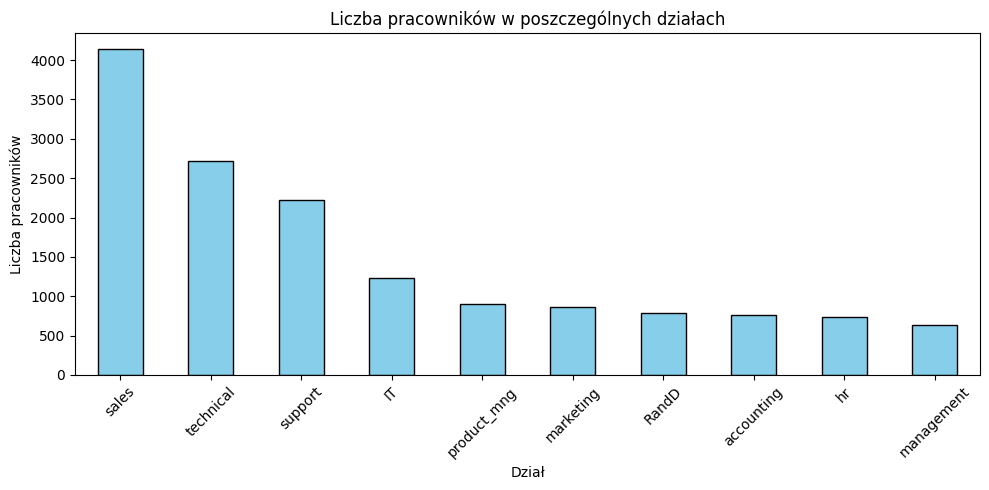

In [7]:
pracownicy_dzialy = hr["sales"].value_counts()
print(pracownicy_dzialy)

plt.figure(figsize=(10, 5))
pracownicy_dzialy.plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Liczba pracowników w poszczególnych działach")
plt.xlabel("Dział")
plt.ylabel("Liczba pracowników")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4. Liczba pracowników, Którzy zwolnili się i jaki to jest procent danego działu

In [8]:
zwolnieni_dzialy = hr.groupby("sales")["left"].agg(liczba_zwolnionych="sum", procent_dzialu="mean")
zwolnieni_dzialy["procent_dzialu"] = (zwolnieni_dzialy["procent_dzialu"] * 100).round(2)

print(zwolnieni_dzialy)

             liczba_zwolnionych  procent_dzialu
sales                                          
IT                          273           22.25
RandD                       121           15.37
accounting                  204           26.60
hr                          215           29.09
management                   91           14.44
marketing                   203           23.66
product_mng                 198           21.95
sales                      1014           24.49
support                     555           24.90
technical                   697           25.62


5. Liczba pracowników, którzy otrzymali awans i jaki to procent danego działu

In [9]:
awanse_dzialy = hr.groupby("sales")["promotion_last_5years"].agg(liczba_awansow="sum", procent_dzialu="mean")
awanse_dzialy["procent_dzialu"] = (awanse_dzialy["procent_dzialu"] * 100).round(2)

print(awanse_dzialy)

             liczba_awansow  procent_dzialu
sales                                      
IT                        3            0.24
RandD                    27            3.43
accounting               14            1.83
hr                       15            2.03
management               69           10.95
marketing                43            5.01
product_mng               0            0.00
sales                   100            2.42
support                  20            0.90
technical                28            1.03


6. Macierz korelacji i mapa ciepła


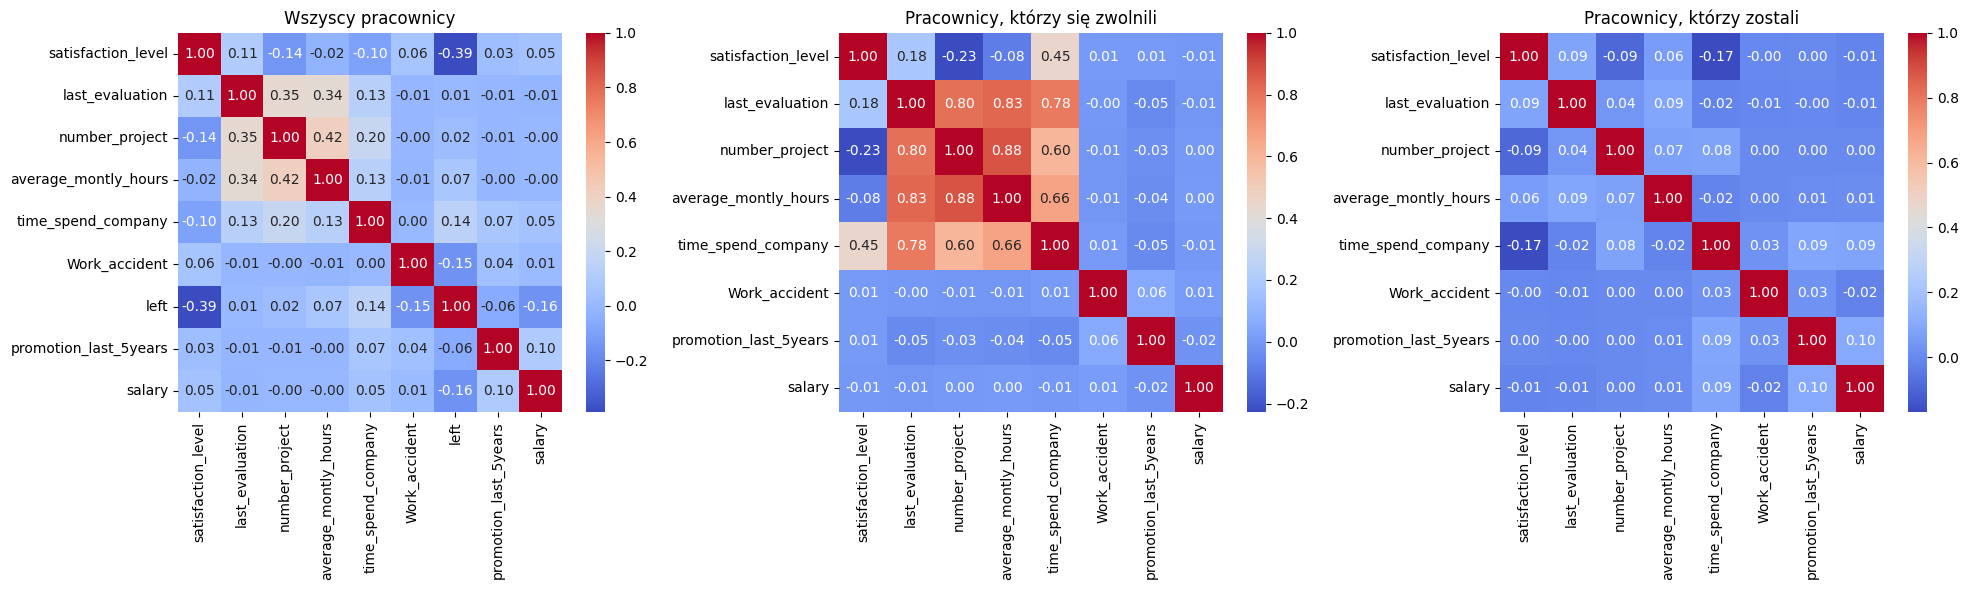

In [10]:
hr_numeryczne = hr.copy()
hr_numeryczne["salary"] = hr_numeryczne["salary"].map({"low": 1, "medium": 2, "high": 3})
hr_numeryczne = hr_numeryczne.drop(columns=["sales"])

korelacja_wszyscy = hr_numeryczne.corr()
korelacja_zwolnieni = hr_numeryczne[hr_numeryczne["left"] == 1].drop(columns=["left"]).corr()
korelacja_zostali = hr_numeryczne[hr_numeryczne["left"] == 0].drop(columns=["left"]).corr()

fig, osie = plt.subplots(1, 3, figsize=(20, 6))

sns.heatmap(korelacja_wszyscy, annot=True, fmt=".2f", cmap="coolwarm", ax=osie[0])
osie[0].set_title("Wszyscy pracownicy")

sns.heatmap(korelacja_zwolnieni, annot=True, fmt=".2f", cmap="coolwarm", ax=osie[1])
osie[1].set_title("Pracownicy, którzy się zwolnili")

sns.heatmap(korelacja_zostali, annot=True, fmt=".2f", cmap="coolwarm", ax=osie[2])
osie[2].set_title("Pracownicy, którzy zostali")

plt.tight_layout()
plt.show()

7. Badanie związku między poziomem satysfakcji a tym, czy pracownik opuścił firmę

a) Korelacja satysfakcja vs odejście: -0.3884
b) Test t-Studenta -> t = 51.6128, p-value = 0.0000e+00


/tmp/ipykernel_1177/1854292009.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=hr, x="left", y="satisfaction_level", palette=["lightblue", "lightpink"])


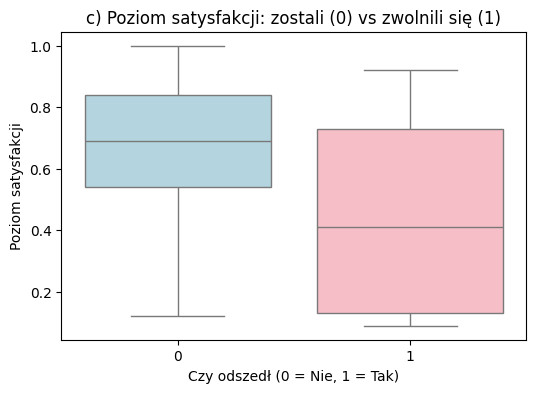

In [16]:
# a) korelacja między poziomem satysfakcji a decyzją o odejściu
korelacja_sat_left = hr["satisfaction_level"].corr(hr["left"])
print(f"a) Korelacja satysfakcja vs odejście: {korelacja_sat_left:.4f}")

# b) test t-Studenta
sat_zostali = hr[hr["left"] == 0]["satisfaction_level"]
sat_zwolnieni = hr[hr["left"] == 1]["satisfaction_level"]
t_stat, p_val = stats.ttest_ind(sat_zostali, sat_zwolnieni)
print(f"b) Test t-Studenta -> t = {t_stat:.4f}, p-value = {p_val:.4e}")

# c) porównanie rozkładów na wykresie
plt.figure(figsize=(6, 4))
sns.boxplot(data=hr, x="left", y="satisfaction_level", palette=["lightblue", "lightpink"])
plt.title("c) Poziom satysfakcji: zostali (0) vs zwolnili się (1)")
plt.xlabel("Czy odszedł (0 = Nie, 1 = Tak)")
plt.ylabel("Poziom satysfakcji")
plt.show()

8. Badanie, czy wynagrodzenie wpływa na rotację pracowników

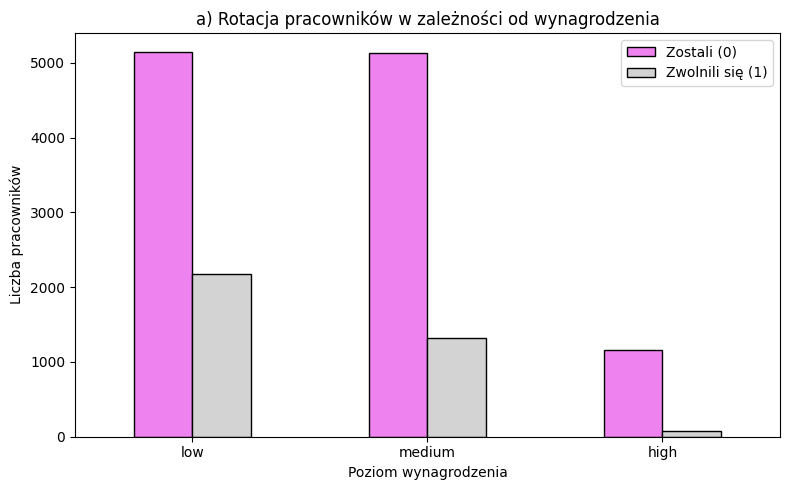

b) Procent odejść w grupach płacowych:
 salary
low       29.69
medium    20.43
high       6.63
Name: left, dtype: float64

c) Test chi-kwadrat -> chi2 = 381.2250, p-value = 1.6521e-83


In [29]:
tabela_plac = pd.crosstab(hr["salary"], hr["left"]).reindex(["low", "medium", "high"])

# a) wizualizacja rozkładu wynagrodzenia w zależności od rotacji
tabela_plac.plot(kind="bar", color=["violet", "lightgrey"], edgecolor="black", figsize=(8, 5))
plt.title("a) Rotacja pracowników w zależności od wynagrodzenia")
plt.xlabel("Poziom wynagrodzenia")
plt.ylabel("Liczba pracowników")
plt.xticks(rotation=0)
plt.legend(["Zostali (0)", "Zwolnili się (1)"])
plt.tight_layout()
plt.show()

# b) procent pracowników, którzy odeszli, w różnych grupach płacowych
procent_odejsc_place = (hr.groupby("salary")["left"].mean() * 100).reindex(["low", "medium", "high"]).round(2)
print("b) Procent odejść w grupach płacowych:\n", procent_odejsc_place)

# c) test chi-kwadrat
chi2, p_chi2, _, _ = stats.chi2_contingency(tabela_plac)
print(f"\nc) Test chi-kwadrat -> chi2 = {chi2:.4f}, p-value = {p_chi2:.4e}")

9. Testu T-Studenta - porównanie poziomu satysfakcji między pracownikami, którzy otrzymali awans, a tymi, którzy nie otrzymali.

In [21]:
sat_awans = hr[hr["promotion_last_5years"] == 1]["satisfaction_level"]
sat_bez_awansu = hr[hr["promotion_last_5years"] == 0]["satisfaction_level"]

t_awans, p_awans = stats.ttest_ind(sat_awans, sat_bez_awansu)
print(f"Test t-Studenta (awans vs brak awansu) -> t = {t_awans:.4f}, p-value = {p_awans:.4f}")

Test t-Studenta (awans vs brak awansu) -> t = 3.1367, p-value = 0.0017


10. Kategoryzacja oceny poziomu satysfakcji

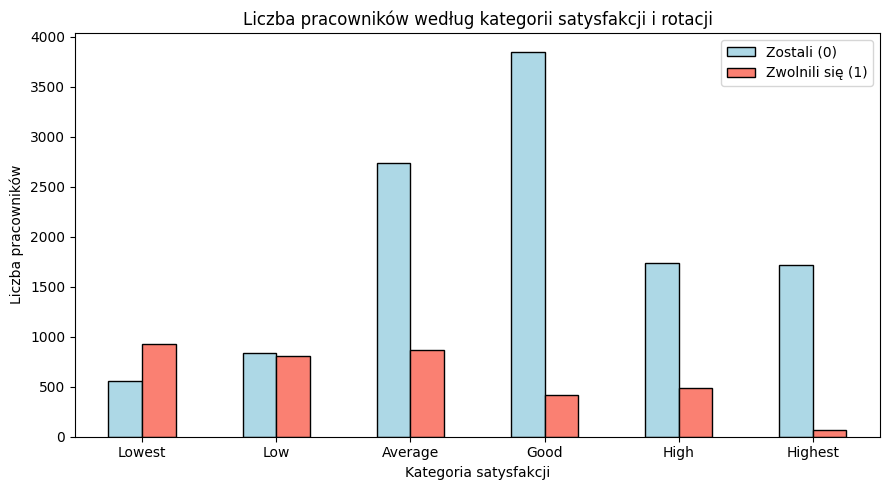

In [24]:
przedzialy = [0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0]
etykiety = ["Lowest", "Low", "Average", "Good", "High", "Highest"]

hr["kategoria_satysfakcji"] = pd.cut(hr["satisfaction_level"], bins=przedzialy, labels=etykiety)
zestawienie_kategorii = pd.crosstab(hr["kategoria_satysfakcji"], hr["left"])

zestawienie_kategorii.plot(kind="bar", color=["lightblue", "salmon"], edgecolor="black", figsize=(9, 5))
plt.title("Liczba pracowników według kategorii satysfakcji i rotacji")
plt.xlabel("Kategoria satysfakcji")
plt.ylabel("Liczba pracowników")
plt.xticks(rotation=0)
plt.legend(["Zostali (0)", "Zwolnili się (1)"])
plt.tight_layout()
plt.show()

Zadanie 4


Korzystając ze zbioru UNSW-NB15, przeanalizuj i odpowiedz czy jest różnica między zwykłym ruchem sieciowym a atakami. Wczytaj dane i sprawdź czy występują puste dane (NaN), jeżeli tak to usuń rekordy.

1. Oblicz liczebność ruchu prawidłowego (label=0) oraz ruchu związanego z atakami (label=1)

2. Dla kolumny sbytes oblicz: średnią, medianę, odchylenie standardowe oraz zidentyfikuj wartości ekstremalne (minima i maksymalne)

3. Przedstaw na histogramie wartości dla kolumny sbytes dla ruchu normalnego i ataków.

4. Dodaj nową kolumnę log_sbytes, którą uzupełnisz w następujący sposób: log_sbytes = np.log1p(sbytes). Przedstaw nową kolumnę na wykresie dla obydwu badanych grup.

5. Wylosuj po 2000 rekordów z każdej z grup i przeprowadź dwustronny test t-studenta dla prób niezależnych dla zmiennej lon_sbytes. Sprawdź hipotezę czy czy sam wolumen przesłanych danych od źródła do celu jest wiarygodną metryką do budowy reguł detekcyjnych.

Wczytanie i czyszczenie zbioru danych

In [31]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

file_path = "UNSW_NB15_training-set.csv"

df = kagglehub.load_dataset(  KaggleDatasetAdapter.PANDAS,  "mrwellsdavid/unsw-nb15",  file_path,)

print("First 5 records:", df.head())

print("Braki danych (NaN):", df.isna().sum().sum())
dane_siec = df.dropna().copy()

/tmp/ipykernel_1177/2324539979.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(  KaggleDatasetAdapter.PANDAS,  "mrwellsdavid/unsw-nb15",  file_path,)


Using Colab cache for faster access to the 'unsw-nb15' dataset.
First 5 records:    id       dur proto service state  spkts  dpkts  sbytes  dbytes  \
0   1  0.000011   udp       -   INT      2      0     496       0   
1   2  0.000008   udp       -   INT      2      0    1762       0   
2   3  0.000005   udp       -   INT      2      0    1068       0   
3   4  0.000006   udp       -   INT      2      0     900       0   
4   5  0.000010   udp       -   INT      2      0    2126       0   

          rate  ...  ct_dst_sport_ltm  ct_dst_src_ltm  is_ftp_login  \
0   90909.0902  ...                 1               2             0   
1  125000.0003  ...                 1               2             0   
2  200000.0051  ...                 1               3             0   
3  166666.6608  ...                 1               3             0   
4  100000.0025  ...                 1               3             0   

   ct_ftp_cmd  ct_flw_http_mthd  ct_src_ltm  ct_srv_dst  is_sm_ips_ports  \
0

1. Liczebność ruchu prawidłowego oraz ruchu związanego z atakami


In [32]:
liczebnosc = dane_siec["label"].value_counts()

print(f"Ruch prawidłowy (label=0): {liczebnosc[0]}")
print(f"Ruch związany z atakami (label=1): {liczebnosc[1]}")

Ruch prawidłowy (label=0): 37000
Ruch związany z atakami (label=1): 45332


2. Średnia, mediana, odchylenie standardowe i wartości ekstremalne dla kolumny sbytes

In [33]:
statystyki_sbytes = dane_siec["sbytes"].agg(["mean", "median", "std", "min", "max"])
print(statystyki_sbytes)

mean      7.993908e+03
median    5.340000e+02
std       1.716423e+05
min       2.400000e+01
max       1.435577e+07
Name: sbytes, dtype: float64


3. Histogram wartości dla kolumny sbytes dla ruchu normalnego i ataków

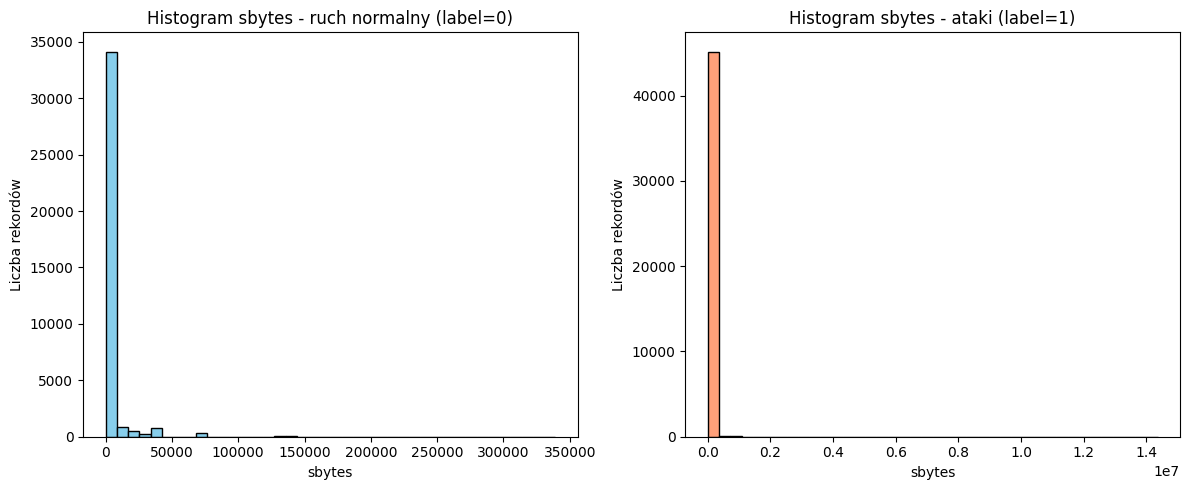

In [34]:
ruch_normalny = dane_siec[dane_siec["label"] == 0]
ruch_ataki = dane_siec[dane_siec["label"] == 1]

fig, osie = plt.subplots(1, 2, figsize=(12, 5))

osie[0].hist(ruch_normalny["sbytes"], bins=40, color="skyblue", edgecolor="black")
osie[0].set_title("Histogram sbytes - ruch normalny (label=0)")
osie[0].set_xlabel("sbytes")
osie[0].set_ylabel("Liczba rekordów")

osie[1].hist(ruch_ataki["sbytes"], bins=40, color="lightsalmon", edgecolor="black")
osie[1].set_title("Histogram sbytes - ataki (label=1)")
osie[1].set_xlabel("sbytes")
osie[1].set_ylabel("Liczba rekordów")

plt.tight_layout()
plt.show()

4. Dodanie kolumny log_sbytes

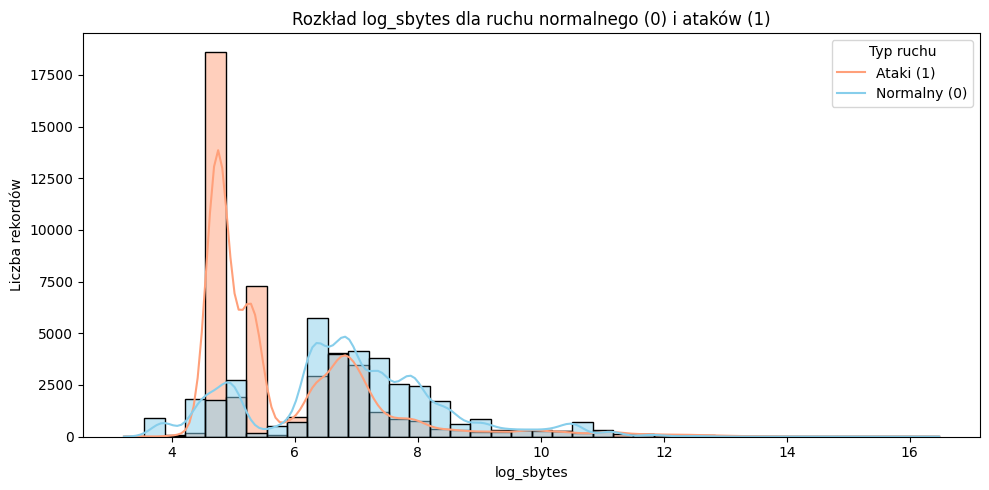

In [35]:
dane_siec["log_sbytes"] = np.log1p(dane_siec["sbytes"])

plt.figure(figsize=(10, 5))
sns.histplot(
    data=dane_siec,
    x="log_sbytes",
    hue="label",
    bins=40,
    kde=True,
    palette=["skyblue", "lightsalmon"]
)
plt.title("Rozkład log_sbytes dla ruchu normalnego (0) i ataków (1)")
plt.xlabel("log_sbytes")
plt.ylabel("Liczba rekordów")
plt.legend(title="Typ ruchu", labels=["Ataki (1)", "Normalny (0)"])
plt.tight_layout()
plt.show()

5. Test T-studentaczy sam wolumen przesłanych danych od źródła do celu jest wiarygodną metryką do budowy reguł detekcyjnych

In [37]:
proba_normalny = dane_siec[dane_siec["label"] == 0]["log_sbytes"].sample(n=2000, random_state=42)
proba_ataki = dane_siec[dane_siec["label"] == 1]["log_sbytes"].sample(n=2000, random_state=42)

t_stat, p_val = stats.ttest_ind(proba_normalny, proba_ataki)
print(f"Test t-Studenta dla log_sbytes -> t = {t_stat:.4f}, p-value = {p_val:.4e}")

Test t-Studenta dla log_sbytes -> t = 19.3238, p-value = 1.3052e-79


Wartość p-value jest znacznie mniejsza od 0.05, więc różnica w rozkładzie log_sbytes między ruchem normalnym a atakami jest istotna statystycznie. Mimo to na wykresie widać wyraźne nakładanie się obu rozkładów w wielu przedziałach, dlatego sam wolumen przesłanych danych nie jest wystarczająco wiarygodną metryką do samodzielnego tworzenia reguł detekcyjnych - generowałby sporo fałszywych alarmów lub przepuszczał część ataków.